9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 2.0494
Epoch 2/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.2778


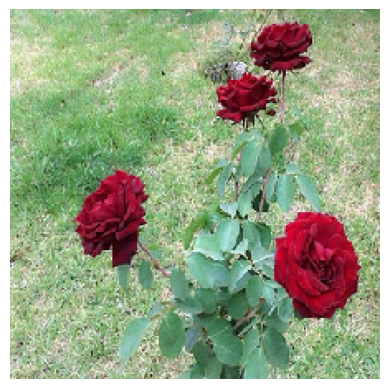

Generated Caption: a a of roses


In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, Model

# Load a small image-caption dataset

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
path = tf.keras.utils.get_file("flowers.tgz", url)

root = os.path.join(os.path.dirname(path), "flower_photos")

if not os.path.exists(root):
  with tarfile.open(path, "r:gz") as tar:
    tar.extractall(os.path.dirname(path))


files, captions = [], []

for folder in os.listdir(root):
    folder_path = os.path.join(root, folder)
    if os.path.isdir(folder_path):
      for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
          files.append(os.path.join(folder_path, file))
          captions.append("a photo of " + folder.replace("_", " "))

files, captions = files[:100], captions[:100]
captions = ["startseq " + c + " endseq" for c in captions]

tokenizer = Tokenizer()
tokenizer.fit_on_texts(captions)
seq = tokenizer.texts_to_sequences(captions)
max_len = max(len(s) for s in seq)
vocab = len(tokenizer.word_index) + 1
cnn = MobileNetV2(weights="imagenet", include_top=False,pooling="avg", input_shape=(224, 224, 3))
cnn.trainable = False
features = []
for f in files:
  img = tf.keras.utils.load_img(f, target_size=(224, 224))
  img = tf.keras.utils.img_to_array(img)
  img = preprocess_input(img)
  features.append(cnn.predict(img[None, ...], verbose=0)[0])
features = np.array(features)
X_img, X_seq, y = [], [], []
for i, s in enumerate(seq):
  for j in range(1, len(s)):
    X_img.append(features[i])
    X_seq.append(s[:j])
    y.append(s[j])

X_seq = pad_sequences(X_seq, maxlen=max_len, padding="post")
X_img, y = np.array(X_img), np.array(y)

image_input = layers.Input(shape=(1280,))
image_features = layers.Dense(128, activation="relu")(image_input)
text_input = layers.Input(shape=(max_len,))
text_features = layers.Embedding(vocab, 128, mask_zero=True)(text_input)
text_features = layers.LSTM(128)(text_features)
combined = layers.Add()([image_features, text_features])
output = layers.Dense(vocab, activation="softmax")(combined)
model = Model([image_input, text_input], output)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.fit([X_img, X_seq], y, epochs=2, batch_size=32)

def generate_caption(feature):
  sentence = "startseq"
  for _ in range(max_len):
    s = tokenizer.texts_to_sequences([sentence])[0]
    s = pad_sequences([s], maxlen=max_len, padding="post")
    pred = model.predict([feature[None, :], s], verbose=0)
    word = tokenizer.index_word.get(np.argmax(pred), "")
    if not word or word == "endseq":
      break
    sentence += " " + word
  return sentence.replace("startseq", "").strip()
i = 0
img = tf.keras.utils.load_img(files[i], target_size=(224, 224))
plt.imshow(img)
plt.axis("off")
plt.show()
print("Generated Caption:", generate_caption(features[i]))
